In [103]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [104]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_v3 import Moire
import utils

In [105]:
sys = Moire(theta_deg=1.0, psi_deg=-65.0, V=6.6, n_shells=8)

Text(0.5, 1.0, '$\\mathbf{R}_0 = \\left(0, a_M\\right)$')

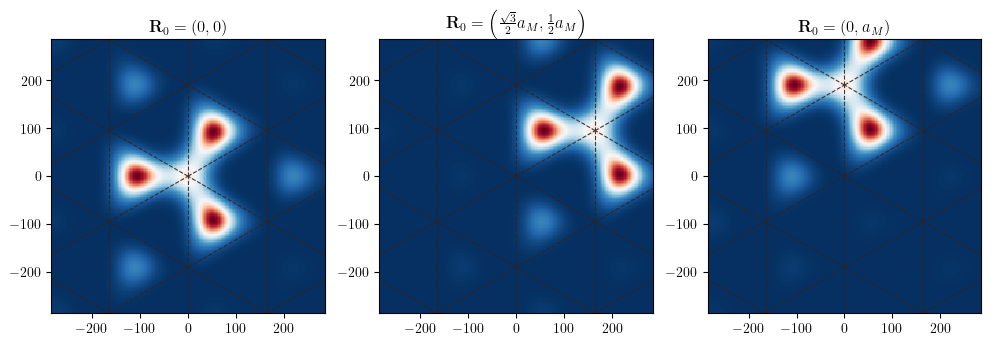

In [106]:
scale = 1.5
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 200
Ny = 200

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=20, Ny=20)


fig, ax = plt.subplots(1, 3, figsize=(12, 8))
im = sys.plot_wannier_function(ax[0], X, Y, k_points)
sys.plot_triangular_lattice(ax[0], extent)
ax[0].set_title(r"$\mathbf{R}_0 = \left(0, 0\right)$")

im = sys.plot_wannier_function(ax[1], X, Y, k_points, R0=np.array([np.sqrt(3) * sys.aM / 2, sys.aM / 2]))
sys.plot_triangular_lattice(ax[1], extent)
ax[1].set_title(r"$\mathbf{R}_0 = \left(\frac{\sqrt{3}}{2}a_M, \frac{1}{2}a_M\right)$")

im = sys.plot_wannier_function(ax[2], X, Y, k_points, R0=np.array([0.0, sys.aM]))
sys.plot_triangular_lattice(ax[2], extent)
ax[2].set_title(r"$\mathbf{R}_0 = \left(0, a_M\right)$")

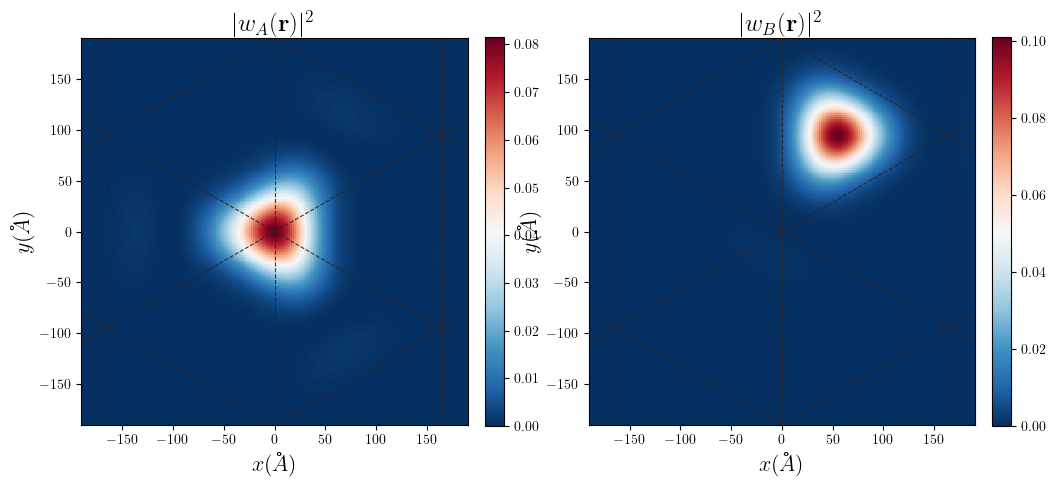

In [107]:
scale = 1.0
extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]

Nx = 200
Ny = 200

x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
X, Y = np.meshgrid(x, y)

k_points = sys.mesh_k_unit_cell(Nx=21, Ny=21)

## Trial functions centers
RA = np.zeros(2)
RB = (sys.a1 + sys.a2) / 3

wanniers = sys.wannier_wavefunction_2band(X, Y, k_points, trial_centers= np.array([RA, RB]))

wannier1 = wanniers[0, :, :]
wannier2 = wanniers[1, :, :]


fig, ax = plt.subplots(1, 2, figsize=(12, 8))
im = sys.plot_wannier_function(ax[0], X, Y, k_points)

ax[0].set_title(r"$|w_A(\mathbf{r})|^2$", fontsize=18)
ax[0].set_xlabel(r'$x (\AA)$', fontsize=16)
ax[0].set_ylabel(r'$y (\AA)$', fontsize=16)
extent = [X.min(), X.max(), Y.min(), Y.max()]
sys.plot_triangular_lattice(ax[0], extent)
im0 = sys.plot_wavefunction(ax[0], wannier1, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im0,fraction=0.046, pad=0.04)

ax[1].set_title(r"$|w_B(\mathbf{r})|^2$", fontsize=18)
ax[1].set_xlabel(r'$x (\AA)$', fontsize=16)
ax[1].set_ylabel(r'$y (\AA)$', fontsize=16)
sys.plot_triangular_lattice(ax[1], extent)
im1 = sys.plot_wavefunction(ax[1], wannier2, extent, norm=None, cmap='RdBu_r')
plt.colorbar(im1, fraction=0.046, pad=0.04)
plt.savefig("plots/wanniers_two_bands.pdf", dpi=300, bbox_inches='tight')

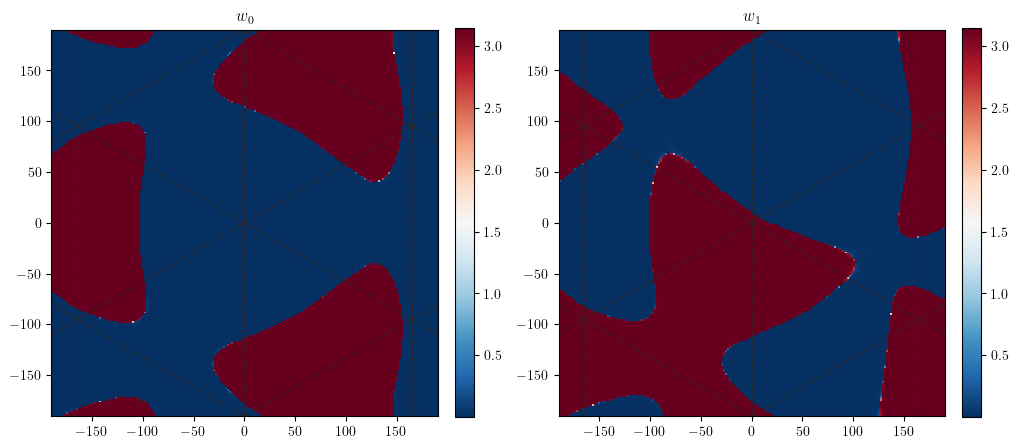

In [108]:
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
im = sys.plot_wannier_function(ax[0], X, Y, k_points)

ax[0].set_title(r"$w_0$")
extent = [X.min(), X.max(), Y.min(), Y.max()]
sys.plot_triangular_lattice(ax[0], extent)
im0 = sys.plot_wavefunction_phase(ax[0], wannier1, extent, cmap='RdBu_r')
plt.colorbar(im0, fraction=0.046, pad=0.04)

ax[1].set_title(r"$w_1$")
sys.plot_triangular_lattice(ax[1], extent)
im1 = sys.plot_wavefunction_phase(ax[1], wannier2, extent, cmap='RdBu_r')
plt.colorbar(im1, fraction=0.046, pad=0.04)

### Quantum Metric

In [109]:
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
k_points = np.column_stack([KX.ravel(), KY.ravel()])
g_xx, g_xy, g_yy = sys.quantum_metric(k_points)

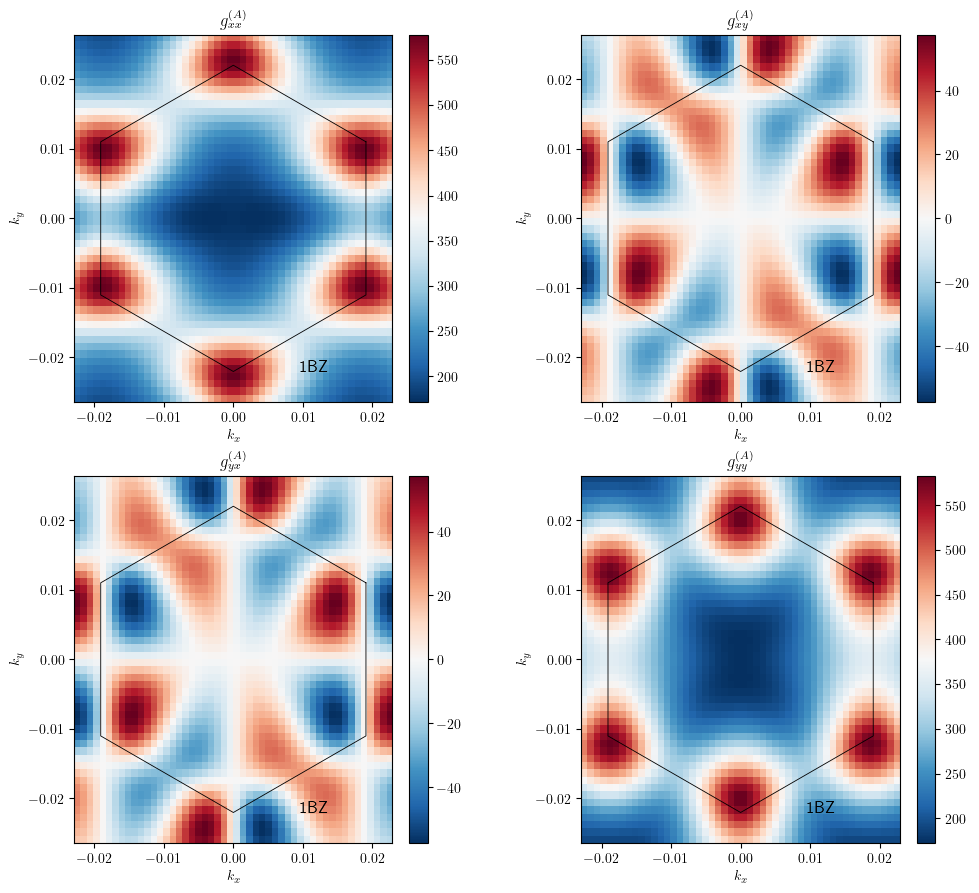

In [110]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10.5))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_metric_band(ax, KX, KY, band=0, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/quantum_metric_band_A.pdf", dpi=300, bbox_inches='tight')

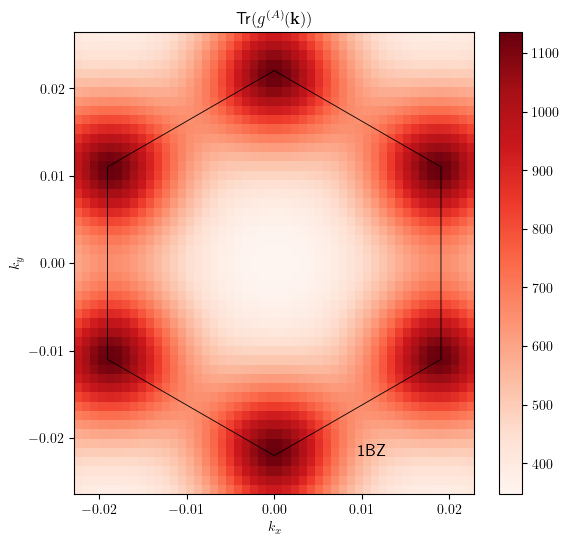

In [111]:
fig, ax = plt.subplots(figsize=(8, 6))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric_band(ax, KX, KY, band=0, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/trace_quantum_metric_band_A.pdf", dpi=300, bbox_inches='tight')

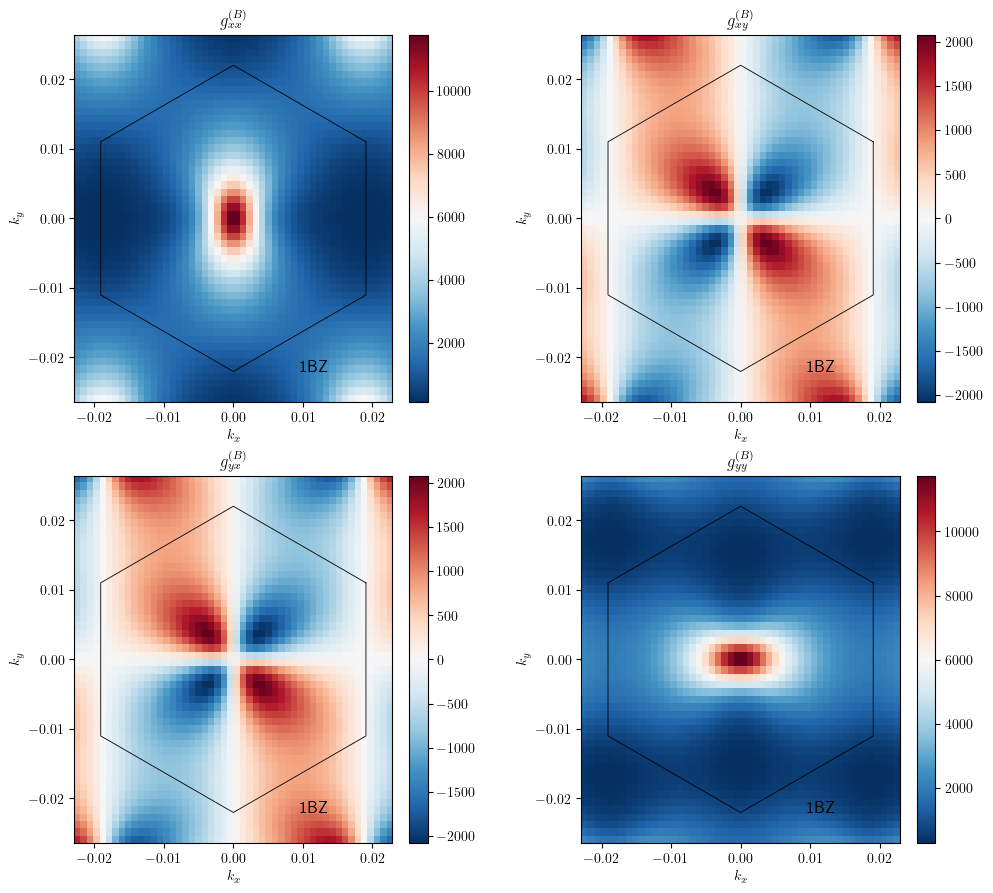

In [112]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10.5))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_metric_band(ax, KX, KY, band=1, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/quantum_metric_band_B.pdf", dpi=300, bbox_inches='tight')

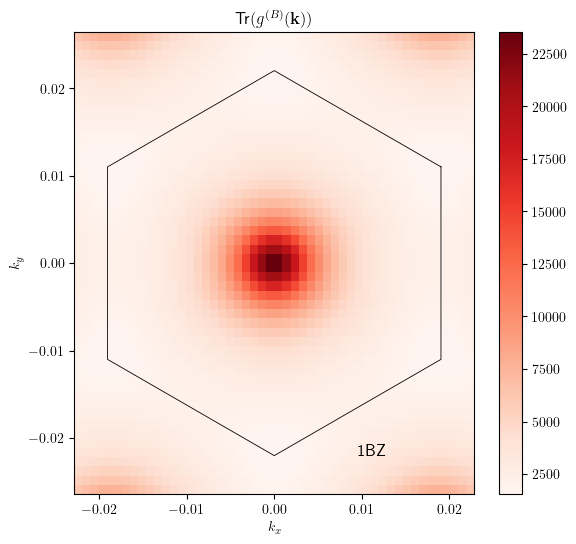

In [113]:
fig, ax = plt.subplots(figsize=(8, 6))
scale = 1.2
kx = np.linspace(-scale * sys.kappa_pp[0], scale * sys.kappa_pp[0], 50)
ky = np.linspace(-scale * sys.kappa_p[1], scale * sys.kappa_p[1], 50)
KX, KY = np.meshgrid(kx, ky)
sys.plot_trace_metric_band(ax, KX, KY, band=1, mask_bz=False)

plt.xlabel(r'$k_x$')
plt.ylabel(r'$k_y$')
plt.savefig("plots/trace_quantum_metric_band_B.pdf", dpi=300, bbox_inches='tight')